# E03 · AdaBN: adapting the model's normalisation layers to the test images

**Idea.** The network contains about 50 normalisation layers (BatchNorm). Each one learned during
training what "normal" activations look like: an average and a spread per channel, measured on the
**training images**. The Kaggle images look different (no haze, more contrast), so every one of these
layers receives values that look "abnormal" to it, and the errors add up through the network.

**AdaBN** (Li et al., 2016) runs the Kaggle images through the network once and lets every
normalisation layer **re-measure its average and spread on the Kaggle images**. All learned filters
stay exactly the same. No labels, no training, about one minute.

**Risk.** This is the same idea as the tried variant in `E01_baseline` (normalising the Kaggle images with their
own statistics), just inside the network. That variant failed (47.8% vs 56.5%) because the Kaggle set
contains much more water (23.5% vs 9% in training), which skews its statistics. So two versions are
compared:

| Version | Statistics measured on |
|---|---|
| `none` | training images (the model as it is, 64.06% on Kaggle) |
| `adabn_all` | all 4,232 Kaggle images |
| `adabn_balanced` | Kaggle images with the **same water share as the training data** (all land images + a random subset of water images) |

**Base model:** `runs/2026-10-12_0910_hist_split_effb0` (EfficientNet-B0 trained on `hist_split`-corrected
images). Each AdaBN version is saved as its own run folder with a `submission.csv`.

## 1 · Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
from src.data import CLASSES, PROJECT_ROOT, band_index, load_split, load_test, load_train
from src.plot_style import MUTED, TEST_COLOR, TRAIN_COLOR, apply_style
from src.preprocessing import land_mask, load_matcher
from src.training import (adapt_batchnorm, load_run, new_run_dir, predict_proba, predict_views,
                          to_device_images, write_submission)
from src.utils import describe_device, get_device, seed_everything

apply_style()

BASE_RUN = "runs/2026-10-12_0910_hist_split_effb0"
# Saved AdaBN runs: loaded instead of re-measuring. Set to None to adapt again (creates new run folders).
LOAD_RUNS = {"adabn_all": "runs/2026-10-12_1009_adabn_all_hist_split",
             "adabn_balanced": "runs/2026-10-12_1009_adabn_balanced_hist_split"}
SEED = 42
seed_everything(SEED)
device = get_device()
print("Device:", describe_device(device))

base_config = json.loads((PROJECT_ROOT / BASE_RUN / "config.json").read_text())
base_metrics = json.loads((PROJECT_ROOT / BASE_RUN / "metrics.json").read_text())
print(f"Base run: {BASE_RUN}  (Kaggle public {base_metrics['kaggle_public_score']:.2%})")

Device: Apple GPU (MPS)
Base run: runs/2026-10-12_0910_hist_split_effb0  (Kaggle public 64.06%)


## 2 · Data

Kaggle images are used as they are. Validation images are corrected with `hist_split`, exactly as
during training of the base model; they are used for a sanity check of the method.

In [2]:
X_all, meta = load_train()
X_kaggle, test_ids = load_test()
split = load_split()
matcher = load_matcher(PROJECT_ROOT / "artifacts" / "preprocessing" / f"{base_config['preprocess']}.json")
band_idx = [band_index(b) for b in base_config["bands"]]

rows_tr = np.flatnonzero(split["split"].values == "train")
rows_va = np.flatnonzero(split["split"].values == "val")
X_va = matcher(np.asarray(X_all[rows_va]))[:, band_idx]
y_va = split["label_id"].values[rows_va]
X_kg = np.asarray(X_kaggle)[:, band_idx]

va_images = to_device_images(X_va, device)
kg_images = to_device_images(X_kg, device)

# Water share of the training split decides the balanced subset
water_share_train = 1 - land_mask(np.asarray(X_all[rows_tr])).mean()
kg_land = land_mask(np.asarray(X_kaggle))
n_water = int(round(kg_land.sum() * water_share_train / (1 - water_share_train)))
rng = np.random.default_rng(SEED)
balanced_idx = np.sort(np.r_[np.flatnonzero(kg_land), rng.choice(np.flatnonzero(~kg_land), n_water, replace=False)])

print(f"Water share: training split {water_share_train:.1%}, Kaggle {1 - kg_land.mean():.1%}")
print(f"Balanced subset: {kg_land.sum():,} land + {n_water:,} water = {len(balanced_idx):,} Kaggle images "
      f"({n_water / len(balanced_idx):.1%} water)")

Water share: training split 9.0%, Kaggle 23.5%
Balanced subset: 3,237 land + 320 water = 3,557 Kaggle images (9.0% water)


## 3 · Sanity check

Re-measuring the statistics on images from the **same** domain the model was trained on should change
almost nothing. If the validation accuracy stayed the same, the implementation is correct.

In [3]:
model, normalizer, _ = load_run(PROJECT_ROOT / BASE_RUN, device)
acc_before = (predict_proba(model, va_images, normalizer).argmax(1) == y_va).mean()
adapt_batchnorm(model, va_images, normalizer)
acc_after = (predict_proba(model, va_images, normalizer).argmax(1) == y_va).mean()
print(f"Validation accuracy: {acc_before:.2%} before, {acc_after:.2%} after AdaBN on validation images")

Validation accuracy: 98.94% before, 98.99% after AdaBN on validation images


## 4 · Apply AdaBN on Kaggle images

For each version a fresh copy of the base model is loaded, adapted, and used to predict all Kaggle
images with the 8 rotations/flips. Every version is judged without labels:

- **Confidence**: mean probability of the predicted class.
- **View agreement**: share of images where all 8 rotated/flipped versions get the **same** class.
  A model that understands an image should not change its mind when the image is rotated.
- **Class mix**: share of images per predicted class. SeaLake should stay around 24%.
- **Changed vs `none`**: share of images whose predicted class differs from the base model.

In [4]:
versions = {"none": None, "adabn_all": np.arange(len(X_kg)), "adabn_balanced": balanced_idx}
models, views = {}, {}
for name, idx in versions.items():
    if idx is not None and LOAD_RUNS:
        m, norm, _ = load_run(PROJECT_ROOT / LOAD_RUNS[name], device)   # saved adapted weights
    else:
        m, norm, _ = load_run(PROJECT_ROOT / BASE_RUN, device)
        if idx is not None:
            adapt_batchnorm(m, kg_images[torch.from_numpy(idx).to(device)], norm)
    models[name] = m
    views[name] = predict_views(m, kg_images, norm)   # (8, N, 10)

prob = {name: v.mean(0) for name, v in views.items()}
pred = {name: p.argmax(1) for name, p in prob.items()}

def view_agreement(v):
    per_view = v.argmax(2)                      # (8, N)
    return (per_view == per_view[0]).all(0).mean()

summary = pd.DataFrame({
    "confidence (%)": [prob[n].max(1).mean() * 100 for n in versions],
    "view agreement (%)": [view_agreement(views[n]) * 100 for n in versions],
    "SeaLake (%)": [(pred[n] == CLASSES.index("SeaLake")).mean() * 100 for n in versions],
    "changed vs none (%)": [(pred[n] != pred["none"]).mean() * 100 for n in versions],
}, index=list(versions)).round(1)
summary

,confidence (%),view agreement (%),SeaLake (%),changed vs none (%)
none,75.099998,73.0,24.3,0.0
adabn_all,61.500000,50.9,9.5,33.3
adabn_balanced,71.800003,70.2,24.5,17.1


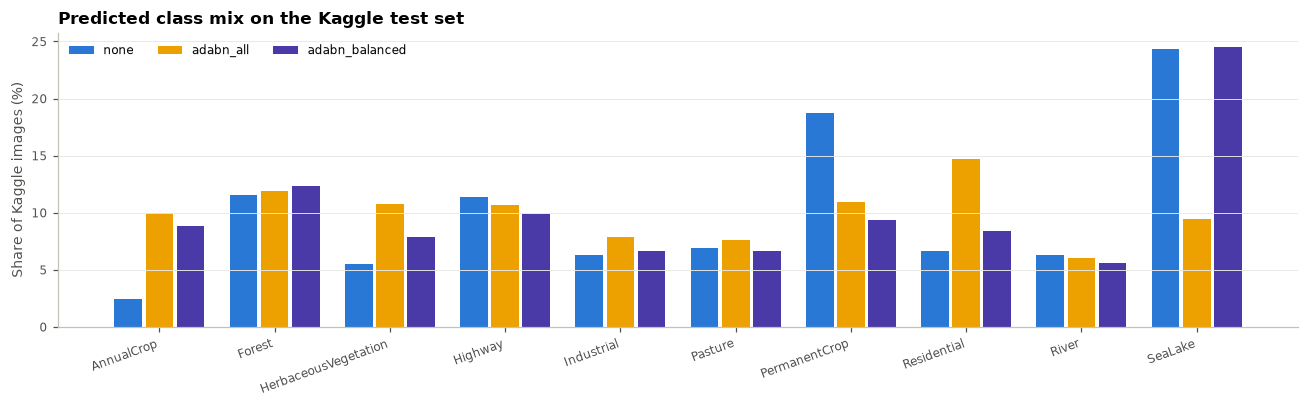

,none,adabn_all,adabn_balanced
AnnualCrop,2.4,10.0,8.8
Forest,11.5,11.9,12.3
HerbaceousVegetation,5.6,10.7,7.8
Highway,11.4,10.7,9.9
Industrial,6.3,7.9,6.6
Pasture,6.9,7.6,6.6
PermanentCrop,18.7,10.9,9.4
Residential,6.7,14.7,8.4
River,6.3,6.1,5.6
SeaLake,24.3,9.5,24.5


In [5]:
mix = pd.DataFrame({n: np.bincount(pred[n], minlength=10) / len(pred[n]) * 100 for n in versions}, index=CLASSES)

fig, ax = plt.subplots(figsize=(12, 3.8))
x = np.arange(10)
w = 0.27
colors = {"none": TRAIN_COLOR, "adabn_all": "#eda100", "adabn_balanced": "#4a3aa7"}
for i, n in enumerate(versions):
    ax.bar(x + (i - 1) * w, mix[n], w - 0.03, color=colors[n], label=n)
ax.set_xticks(x, CLASSES, rotation=20, ha="right")
ax.set_ylabel("Share of Kaggle images (%)")
ax.set_title("Predicted class mix on the Kaggle test set", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(ncol=3)
plt.tight_layout()
plt.show()
mix.round(1)

In [6]:
# Where do the predictions move? Rows: base model, columns: adabn_balanced
pd.crosstab(pd.Series([CLASSES[i] for i in pred["none"]], name="none"),
            pd.Series([CLASSES[i] for i in pred["adabn_balanced"]], name="adabn_balanced"))

adabn_balanced,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
none,,,,,,,,,,
AnnualCrop,102,0,0,0,0,1,0,0,0,0
Forest,7,443,33,0,0,4,0,0,1,0
HerbaceousVegetation,0,9,215,1,1,0,2,6,1,0
Highway,27,3,7,390,26,4,4,19,1,0
Industrial,1,0,3,0,229,0,0,32,0,0
Pasture,28,18,20,3,6,205,0,3,7,1
PermanentCrop,196,43,46,24,17,66,390,10,0,0
Residential,1,0,1,0,0,0,0,281,0,0
River,12,6,6,1,1,0,0,3,227,9


## 5 · Save the runs

Each version gets its own run folder: adapted weights (`model.pt`), `config.json` with the base run and
the method, `metrics.json` with the label-free measurements, and `submission.csv`.

With `LOAD_RUNS` set, the saved runs are reused and only `submission.csv` is recomputed from their weights.

In [7]:
saved = {}
for name in ["adabn_all", "adabn_balanced"]:
    if LOAD_RUNS:   # runs exist already: only recompute the submission file from the saved weights
        run_dir = PROJECT_ROOT / LOAD_RUNS[name]
        write_submission(prob[name], test_ids, run_dir / "submission.csv")
        saved[name] = run_dir
        print("Recomputed", (run_dir / "submission.csv").relative_to(PROJECT_ROOT))
        continue
    run_dir = new_run_dir(f"{name}_hist_split")
    torch.save({k: v.detach().cpu() for k, v in models[name].state_dict().items()}, run_dir / "model.pt")
    config = {**base_config, "run_name": run_dir.name, "base_run": BASE_RUN, "method": name,
              "bn_statistics_from": "all Kaggle images" if name == "adabn_all"
                                    else f"Kaggle land images + water images at the training water share ({water_share_train:.1%})",
              "n_bn_images": int(len(versions[name]))}
    metrics = {
        "kaggle_mean_confidence": float(prob[name].max(1).mean()),
        "kaggle_view_agreement": float(view_agreement(views[name])),
        "kaggle_changed_vs_base": float((pred[name] != pred["none"]).mean()),
        "kaggle_predicted_mix_pct": mix[name].round(2).to_dict(),
        "kaggle_public_score": None,  # fill in after submitting
    }
    (run_dir / "config.json").write_text(json.dumps(config, indent=2))
    (run_dir / "metrics.json").write_text(json.dumps(metrics, indent=2))
    write_submission(prob[name], test_ids, run_dir / "submission.csv")
    saved[name] = run_dir
    print("Saved", run_dir.relative_to(PROJECT_ROOT))

Recomputed runs/2026-10-12_1009_adabn_all_hist_split/submission.csv
Recomputed runs/2026-10-12_1009_adabn_balanced_hist_split/submission.csv


## 6 · Conclusion

| Version | Confidence | View agreement | SeaLake | Changed vs `none` | Assessment |
|---|---|---|---|---|---|
| `none` (64.06%) | 75.1% | 73.0% | 24.3% | – | reference |
| `adabn_all` | 61.5% | 50.9% | **9.5%** | 33.3% | **probably worse**: water stops looking like water, exactly like the tried variant in `E01_baseline` |
| `adabn_balanced` | 71.8% | 70.2% | 24.5% | 17.1% | **uncertain, plausible**: class mix becomes more realistic |

- **`adabn_all` repeats the failure of that variant.** With 23.5% water in its statistics, SeaLake drops from 24% to 9.5%, and the model becomes unsure (confidence −14 points, only half the images get the same class in all 8 views).
- **`adabn_balanced` keeps water intact** (SeaLake 24.5%) and fixes the base model's most suspicious prediction: PermanentCrop drops from 18.7% to 9.4%, AnnualCrop rises from 2.4% to 8.8% (196 images move from PermanentCrop to AnnualCrop). The class mix is now close to EuroSAT's.
- **But** confidence and view agreement drop slightly (−3 points each). The label-free measurements disagree, so only Kaggle can tell whether `adabn_balanced` is better.

**Kaggle result:** `adabn_balanced` scored **65.28%** (+1.2 points over `E02`, 64.06%), without any retraining.
`adabn_all` was not submitted.

**Lesson:** any method that takes statistics from the Kaggle set must correct for its higher water share.
